In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score, recall_score 
from sklearn.base import clone


sns.set_theme(style="whitegrid")

RANDOM_STATE = 0

In [3]:
# Load dataset & check columns
df = pd.read_csv('../data/clean/cleaned_dataframe.csv')
df.info()

In [5]:
# Drop Unnamed column

df = df.drop(columns="Unnamed: 0")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  str    
 1   cap-color             61069 non-null  str    
 2   cap-shape             61069 non-null  str    
 3   does-bruise-or-bleed  61069 non-null  str    
 4   gill-color            61069 non-null  str    
 5   has-ring              61069 non-null  str    
 6   season                61069 non-null  str    
 7   habitat               61069 non-null  str    
 8   cap-diameter          61069 non-null  float64
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
dtypes: float64(3), str(8)
memory usage: 5.1 MB


In [6]:
# We split the data into train and test

X_mush = df.drop(columns="class")
y_mush = df["class"]

X_train_mush, X_test_mush, y_train_mush, y_test_mush = train_test_split(
    X_mush,
    y_mush,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mush,
)

print("Training observations:", len(X_train_mush))
print("Test observations:", len(X_test_mush))
print("Training features:", list(X_train_mush.columns))

Training observations: 48855
Test observations: 12214
Training features: ['cap-color', 'cap-shape', 'does-bruise-or-bleed', 'gill-color', 'has-ring', 'season', 'habitat', 'cap-diameter', 'stem-height', 'stem-width']


In [7]:
# Split features by type

numeric_features = ["cap-diameter", 'stem-height', 'stem-width']
nominal_features = [    "cap-color", "cap-shape","does-bruise-or-bleed", "gill-color", "has-ring", "season", "habitat"]


In [8]:
# Define the enconder for Nominal features

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_mush[nominal_features])

encoded_train = pd.DataFrame(
    encoder.transform(X_train_mush[nominal_features]),
    columns=encoder.get_feature_names_out(),
    index=X_train_mush.index,
)
display(encoded_train.head())


,cap-color_b,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,...,season_u,season_w,habitat_d,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
1117,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32619,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
12883,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
43050,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
20204,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
# Creating a pipeline for Nominal features

nominal_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

print(nominal_pipeline)

Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [10]:
# Scale Numerical features
scaler = StandardScaler()

scaled_train = pd.DataFrame(
    scaler.fit_transform(X_train_mush[numeric_features]),
    columns=numeric_features,
    index=X_train_mush.index,
)

scaled_test = pd.DataFrame(
    scaler.transform(X_test_mush[numeric_features]),
    columns=numeric_features,
    index=X_test_mush.index,
)

In [11]:
# Creating a pipeline for Numerical features

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', scaler),
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [12]:
# Combine nominal and numerical features

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("nominal", nominal_pipeline, nominal_features),
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

model.fit(X_train_mush, y_train_mush)
y_pred = model.predict(X_test_mush)

In [13]:
y_pred

array(['p', 'e', 'p', ..., 'e', 'e', 'p'], shape=(12214,), dtype=object)

              precision    recall  f1-score   support

      Edible       0.99      0.99      0.99      5436
   Poisonous       0.99      0.99      0.99      6778

    accuracy                           0.99     12214
   macro avg       0.99      0.99      0.99     12214
weighted avg       0.99      0.99      0.99     12214



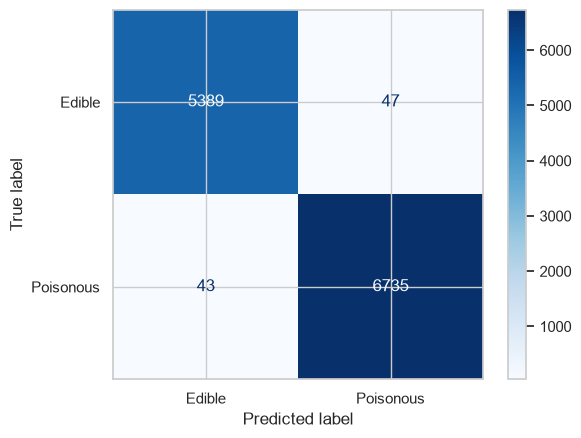

In [14]:
# Evaluate predictions

print(classification_report(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues",
)
plt.show()

In [15]:
# Compare Test and Training accuracy to check if there is overfitting or underfitting

train_accuracy = model.score(X_train_mush, y_train_mush)
test_accuracy = model.score(X_test_mush, y_test_mush)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy:     {test_accuracy:.2%}")
print(f"Accuracy gap:     {(train_accuracy - test_accuracy) * 100:.2f} percentage points")

Training accuracy: 99.37%
Test accuracy:     99.26%
Accuracy gap:     0.10 percentage points


In [16]:
# Check how many mushrooms have been wrongly classified

missed_poisonous = ((y_test_mush == "p") & (y_pred == "e")).sum()
print(f"Poisonous mushrooms predicted as edible: {missed_poisonous}")

Poisonous mushrooms predicted as edible: 43


In [19]:
# Train KNN and generate predictions without scaling
model_unscaled = clone(model)

model_unscaled.set_params(preprocessing__numeric__scaler="passthrough")

model_unscaled.fit(X_train_mush, y_train_mush)

y_pred_unscaled = model_unscaled.predict(X_test_mush)

In [20]:
# Compare both models' overall performance (with and without scaling)
results = []

for scaling, predictions in [
    ("With scaling", y_pred),
    ("Without scaling", y_pred_unscaled),
]:

    results.append({
        "Model": scaling,
        "Accuracy": accuracy_score(y_test_mush, predictions),
        "Macro F1": f1_score(y_test_mush, predictions, average="macro"),
        "Poisonous recall": recall_score(
            y_test_mush, predictions, pos_label="p"
        ),
        "Poisonous predicted as edible": (
            (y_test_mush == "p") & (predictions == "e")
        ).sum(),
    })


comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

,Accuracy,Macro F1,Poisonous recall,Poisonous predicted as edible
Model,,,,
With scaling,0.9926,0.9925,0.9937,43
Without scaling,0.9893,0.9891,0.9904,65


## Conclusions

We used K-Nearest Neighbors (`k=5`) to classify mushrooms as edible or poisonous based on ten features from the secondary dataset. We trained the model on 80% of the data and evaluated it on the remaining 20%, using a stratified split to preserve the class proportions. The preprocessing pipeline was fitted on the training data and then applied to the test data.

### Model performance

The scaled KNN model achieved **99.26% accuracy** and a **macro F1 score of 0.9925** on the test set. It correctly identified **99.37% of poisonous mushrooms**, with **43 poisonous mushrooms classified as edible**. That error count adds context to the high accuracy because it shows how often the model missed the poisonous class.

### Overfitting and underfitting

The high test accuracy and macro F1 give little indication of substantial underfitting. To assess overfitting, we compare training and test accuracy from the final scaled pipeline. **99.37%%** on the training set versus **99.26%** on the test set gives a gap of **0.10 percentage points**. A small gap between two high scores would indicate little evidence of substantial overfitting on this split.

### Effect of scaling

We compared KNN with and without `StandardScaler` on the three numerical features, keeping the train/test split, one-hot encoding, and number of neighbors fixed. Scaling matters for KNN because the model uses distances to find similar mushrooms, and measurements with a larger spread can otherwise have more influence on those distances.

| Test metric | Without scaling | With scaling |
|---|---:|---:|
| Accuracy | 98.93% | 99.26% |
| Macro F1 | 0.9891 | 0.9925 |
| Poisonous recall | 99.04% | 99.37% |
| Poisonous mushrooms predicted as edible | 65 | 43 |

Scaling improved all four metrics on this split. Accuracy increased by **0.33 percentage points**, and the number of poisonous mushrooms classified as edible fell by **22**, a reduction of about **34%**. Based on this comparison, we selected the scaled KNN pipeline for the team's model comparison.